# Laboratorio 09: Bag of Words, Similitud de Coseno e Índice Invertido

## Parte 1: Configuración y Carga de Datos

Se crean las tablas `noticias` y `stopwords` y se cargan `news_es.csv` y `stoplist.txt`.

In [1]:
import psycopg2, pandas as pd, json, time, math, re
import matplotlib.pyplot as plt
from nltk.stem.snowball import SnowballStemmer
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

def connect_db():
  conn = psycopg2.connect(
    dbname="lab9", user="postgres",
    password="postgres", host="localhost", port="5434"
  )
  return conn

In [2]:
conn = connect_db()
cursor = conn.cursor()

cursor.execute("DROP TABLE IF EXISTS noticias;")
cursor.execute("DROP TABLE IF EXISTS stopwords;")

cursor.execute("""
CREATE TABLE noticias (
  id SERIAL PRIMARY KEY,
  url TEXT,
  contenido TEXT,
  categoria VARCHAR(50),
  bag_of_words JSONB
);
""")

cursor.execute("""
CREATE TABLE stopwords (
  id SERIAL PRIMARY KEY,
  word TEXT UNIQUE NOT NULL
);
""")

with open("news_es.csv", encoding="utf-8") as f:
  cursor.copy_expert("COPY noticias (url, contenido, categoria) FROM STDIN WITH (FORMAT csv, HEADER true)", f)

with open("stoplist.txt", encoding="utf-8") as f:
  cursor.copy_expert("COPY stopwords (word) FROM STDIN WITH (FORMAT text)", f)

conn.commit()
cursor.close()
conn.close()

In [3]:
conn = connect_db()
conteo = pd.read_sql("""
  SELECT 'noticias' AS tabla, COUNT(*) AS filas FROM noticias
  UNION ALL
  SELECT 'stopwords', COUNT(*) FROM stopwords;
""", conn)
conn.close()
conteo

,tabla,filas
0,noticias,1217
1,stopwords,608


In [4]:
def fetch_data():
  conn = connect_db()
  df = pd.read_sql("SELECT id, contenido FROM noticias ORDER BY id;", conn)
  conn.close()
  return df

noticias_df = fetch_data()
noticias_df.head()

,id,contenido
0,1,Durante el foro La banca articulador empresari...
1,2,El regulador de valores de China dijo el domin...
2,3,En una industria históricamente masculina como...
3,4,Con el dato de marzo el IPC interanual encaden...
4,5,Ayer en Cartagena se dio inicio a la versión n...


## Parte 2: Preprocesamiento y Bag of Words

In [5]:
stemmer = SnowballStemmer("spanish")

def fetch_stopwords():
  conn = connect_db()
  df = pd.read_sql("SELECT word FROM stopwords;", conn)
  conn.close()
  return set(df["word"])

stopwords = fetch_stopwords()

In [6]:
def preprocess(text, stopwords):
  # Aplicar todos los pasos de preprocesamiento (minúsculas, tokenización, stopwords, stemming)
  text = text.lower()

  words = re.findall(r"[a-záéíóúñü]+", text)

  finales = []
  for word in words:
    if word not in stopwords:
      finales.append(word)

  stems = []
  for word in finales:
    stems.append(stemmer.stem(word))
  return stems

In [7]:
def compute_bow(text, stopwords):
  # Aplicar la función de preprocesamiento y calcular el Bag of Words (frecuencia de términos)
  stemmed_words = preprocess(text, stopwords)

  bow = {}
  for word in stemmed_words:
    if word in bow:
      bow[word] += 1
    else:
      bow[word] = 1
  return bow

In [8]:
def update_bow_in_db(dataframe, stopwords):
  # Actualizar la columna bag_of_words de la tabla noticias con el BoW calculado para cada documento
  conn = connect_db()
  cursor = conn.cursor()
  for index, row in dataframe.iterrows():
    bow = compute_bow(row["contenido"], stopwords)
    bow_json = json.dumps(bow)
    cursor.execute(
      "UPDATE noticias SET bag_of_words = %s WHERE id = %s;",
      (bow_json, int(row["id"]))
    )
  conn.commit()
  cursor.close()
  conn.close()

def fetch_data_bow():
  # Mostrar las primeras 10 filas de la tabla noticias_bow
  conn = connect_db()
  df = pd.read_sql("SELECT * FROM noticias ORDER BY id;", conn)
  conn.close()
  return df

In [9]:
update_bow_in_db(noticias_df, stopwords)
noticias_bow_df = fetch_data_bow()
noticias_bow_df.head(10)

,id,url,contenido,categoria,bag_of_words
0,1,https://www.larepublica.co/redirect/post/3201905,Durante el foro La banca articulador empresari...,Otra,"{'aca': 1, 'adn': 1, 'cas': 1, 'for': 1, 'ret'..."
1,2,https://www.larepublica.co/redirect/post/3210288,El regulador de valores de China dijo el domin...,Regulaciones,"{'dat': 1, 'deb': 1, 'inc': 1, 'med': 1, 'mes'..."
2,3,https://www.larepublica.co/redirect/post/3240676,En una industria históricamente masculina como...,Alianzas,"{'go': 1, 'us': 3, 'air': 1, 'baj': 1, 'ceo': ..."
3,4,https://www.larepublica.co/redirect/post/3342889,Con el dato de marzo el IPC interanual encaden...,Macroeconomia,"{'agu': 1, 'car': 2, 'cas': 1, 'dat': 2, 'ine'..."
4,5,https://www.larepublica.co/redirect/post/3427208,Ayer en Cartagena se dio inicio a la versión n...,Otra,"{'agu': 1, 'cup': 2, 'deb': 2, 'etc': 1, 'for'..."
5,6,https://www.larepublica.co/redirect/post/3225281,El emprendimiento del sector inmobiliario Rent...,Alianzas,"{'us': 2, 'big': 1, 'ceo': 1, 'dat': 1, 'sum':..."
6,7,https://www.bbva.com/es/mx/mexico-y-el-desafio...,El país tiene pendiente generar más y mejores ...,Macroeconomia,"{'ve': 1, 'baj': 1, 'cas': 2, 'dat': 1, 'dej':..."
7,8,https://www.bbva.com/es/podcast-agile-en-la-un...,En el 'podcast' tenemos el placer de entrevist...,Innovacion,"{'agil': 4, 'habl': 1, 'mund': 1, 'nach': 3, '..."
8,9,https://www.bbva.com/es/la-ingenieria-social-e...,"El factor humano, normalmente identificado com...",Innovacion,"{'u': 1, 'ali': 2, 'bas': 1, 'cas': 2, 'cin': ..."
9,10,https://www.bbva.com/es/que-hace-un-developer-...,Los perfiles que se demandan en un banco han e...,Innovacion,"{'are': 1, 'cab': 1, 'cas': 1, 'dat': 2, 'pud'..."


## Parte 3: Búsqueda Booleana, Lineal vs. Índice Invertido

### 3.1 Búsqueda Lineal

Recorre todos los documentos verificando si cada BoW satisface la consulta.

In [10]:
def boolean_search_linear(query, dataframe):
  partes = query.split()
  condicion = partes[1]
  partes.pop(1)
  terminos = " ".join(partes)
  query_stemmeada = preprocess(terminos, stopwords)

  result = []
  for index, row in dataframe.iterrows():
    if condicion == "AND":
      if query_stemmeada[0] in row["bag_of_words"] and query_stemmeada[1] in row["bag_of_words"]:
        result.append(row)
    elif condicion == "OR":
      if query_stemmeada[0] in row["bag_of_words"] or query_stemmeada[1] in row["bag_of_words"]:
        result.append(row)
    else:
      if query_stemmeada[0] in row["bag_of_words"] and not query_stemmeada[1] in row["bag_of_words"]:
        result.append(row)

  return result

In [11]:
consultas_lineales = [
  "economía AND inflación",
  "banca OR finanzas",
  "tecnología AND-NOT inflación",
]

for consulta in consultas_lineales:
  resultado = boolean_search_linear(consulta, noticias_bow_df)
  ids = []
  for row in resultado:
    ids.append(int(row["id"]))
  print(consulta, "->", len(resultado), "documentos")
  print("  primeros ids:", ids[:10])

economía AND inflación -> 244 documentos
  primeros ids: [5, 7, 18, 21, 24, 32, 33, 34, 37, 39]
banca OR finanzas -> 547 documentos
  primeros ids: [1, 2, 5, 9, 10, 12, 13, 15, 16, 17]
tecnología AND-NOT inflación -> 306 documentos
  primeros ids: [12, 13, 14, 15, 16, 17, 19, 20, 23, 28]


### 3.2 Búsqueda con Índice Invertido

In [ ]:
class InvertedIndex:
  def __init__(self):
    self.index = {}
    self.idf = {}
    self.length = {}
    self._docs = {}
    self._bows = {}

  def build_from_db(self, ids=None):
      # Leer desde PostgreSQL todos los bag of words
      conn = connect_db()
      if ids is None:
        df = pd.read_sql("SELECT id, contenido, bag_of_words FROM noticias ORDER BY id;", conn)
      else:
        df = pd.read_sql("SELECT id, contenido, bag_of_words FROM noticias WHERE id = ANY(%s) ORDER BY id;", conn, params=(ids,))
      conn.close()
      # Construir el índice invertido, el idf y la norma (longitud) de cada documento

      # construccion del indice invertido
      for index, row in df.iterrows():
        doc_id = int(row["id"])
        bow = row["bag_of_words"]
        self._docs[doc_id] = row["contenido"]
        self._bows[doc_id] = bow
        for word in bow:
          tf = bow[word]
          if word not in self.index:
            self.index[word] = []
          self.index[word].append((doc_id, tf))

      # construccion del idf
      N = len(self._bows)
      for word in self.index:
        df_word = len(self.index[word])
        self.idf[word] = math.log10(N / df_word)

      # construccion de la norma
      for doc_id in self._bows:
        bow = self._bows[doc_id]
        suma = 0
        for word in bow:
          tf = bow[word]
          w = math.log10(1 + tf) * self.idf[word]
          suma += w * w
        self.length[doc_id] = math.sqrt(suma)

  def L(self, word):
    stems = preprocess(word, stopwords)
    if len(stems) == 0:
      return []
    return self.index.get(stems[0], [])

  def showDocument(self, doc_id, max_chars=80):
    return self._docs.get(doc_id, "")[:max_chars] + "..."

  def showDocuments(self, posting_list, max_chars=80):
    return [self.showDocument(doc_id, max_chars) for doc_id, *_ in posting_list]

  def cosine_search_linear(self, query, top_k=5):
    # Implementar la búsqueda por similitud de coseno lineal
    pass

  def cosine_search(self, query, top_k=5):
    score = {}
    # Implementar la búsqueda por similitud de coseno con índice invertido
    return sorted(score.items(), key=lambda t: t[1], reverse=True)[:top_k]

In [13]:
def AND(list1, list2):
  result = []
  l1 = 0
  l2 = 0
  while True:
    if l1 >= len(list1) or l2 >= len(list2):
      break
    if list1[l1][0] == list2[l2][0]:
      result.append(list1[l1])
      l1 += 1
      l2 += 1
    elif list1[l1][0] < list2[l2][0]:
      l1 += 1
    else:
      l2 += 1
  return result

def OR(list1, list2):
  result = []
  l1 = 0
  l2 = 0
  while True:
    if l1 >= len(list1) or l2 >= len(list2):
      break
    if list1[l1][0] == list2[l2][0]:
      result.append(list1[l1])
      l1 += 1
      l2 += 1
    elif list1[l1][0] < list2[l2][0]:
      result.append(list1[l1])
      l1 += 1
    else:
      result.append(list2[l2])
      l2 += 1

  while l1 < len(list1):
    result.append(list1[l1])
    l1 += 1

  while l2 < len(list2):
    result.append(list2[l2])
    l2 += 1
  return result

def AND_NOT(list1, list2):
  result = []
  l1 = 0
  l2 = 0
  while True:
    if l1 >= len(list1) or l2 >= len(list2):
      break
    if list1[l1][0] == list2[l2][0]:
      l1 += 1
      l2 += 1
    elif list1[l1][0] < list2[l2][0]:
      result.append(list1[l1])
      l1 += 1
    else:
      l2 += 1

  while l1 < len(list1):
    result.append(list1[l1])
    l1 += 1

  return result

In [14]:
idx = InvertedIndex()
idx.build_from_db()

print("documentos:", len(idx._docs))
print("terminos en el indice:", len(idx.index))

documentos: 1217
terminos en el indice: 13330


**Pruebas** (mínimo 5, combinando AND, OR, AND-NOT). Las 3 primeras son las del enunciado y las 3 últimas son propias. Se muestran los 3 primeros documentos de cada resultado.

In [15]:
pruebas = [
  ("sostenibilidad AND (ambiente AND renovables)", AND(idx.L("sostenibilidad"), AND(idx.L("ambiente"), idx.L("renovables")))),
  ("tecnología AND (banca OR finanzas)", AND(idx.L("tecnología"), OR(idx.L("banca"), idx.L("finanzas")))),
  ("economía AND-NOT inflación", AND_NOT(idx.L("economía"), idx.L("inflación"))),
  ("(banca OR finanzas) AND-NOT tecnología", AND_NOT(OR(idx.L("banca"), idx.L("finanzas")), idx.L("tecnología"))),
  ("bitcoin OR (criptomonedas OR blockchain)", OR(idx.L("bitcoin"), OR(idx.L("criptomonedas"), idx.L("blockchain")))),
  ("crédito AND (vivienda AND-NOT pandemia)", AND(idx.L("crédito"), AND_NOT(idx.L("vivienda"), idx.L("pandemia")))),
]

for descripcion, resultado in pruebas:
  print()
  print(descripcion, "->", len(resultado), "documentos")
  print(idx.showDocuments(resultado[:3]))


sostenibilidad AND (ambiente AND renovables) -> 9 documentos
['La importancia que cada día más empresas le otorgan al tema de la sostenibilidad...', 'Esta tipología de energía, clave para la sostenibilidad del planeta, nace de la ...', 'El turismo sostenible persigue desarrollar su actividad generando un impacto mín...']

tecnología AND (banca OR finanzas) -> 174 documentos
['BBVA ha presentado BBVA Spark, su propuesta integral de servicios financieros pa...', 'Con acciones que se comprometen con el desarrollo sostenible, ambas organizacion...', 'El regulador bancario de China dijo que las recientes medidas para frenar el mon...']

economía AND-NOT inflación -> 358 documentos
['Las plataformas de domicilios fueron uno de los jugadores más importantes de la ...', 'El regulador bancario de China dijo que las recientes medidas para frenar el mon...', 'JPMorgan dijo el lunes que los cambios regulatorios chinos eran un problema loca...']

(banca OR finanzas) AND-NOT tecnología -> 373 docum

## Parte 4: Similitud de Coseno, Lineal vs. Índice Invertido

`query_weights` procesa la consulta igual que un documento: calcula su BoW, el peso `log10(1 + tf) × idf` de cada término y su norma. Los términos que no aparecen en la colección se ignoran.

In [16]:
def query_weights(self, query):
  bow_query = compute_bow(query, stopwords)
  weights = {}
  suma = 0
  for word in bow_query:
    if word in self.idf:
      tf = bow_query[word]
      w = math.log10(1 + tf) * self.idf[word]
      weights[word] = w
      suma += w * w
  norma = math.sqrt(suma)
  return weights, norma

InvertedIndex.query_weights = query_weights

### 4.1 Coseno Lineal

Calcula TF-IDF y similitud de coseno contra todos los documentos sin usar el índice. La norma de cada documento se recalcula desde su BoW en cada consulta, sin usar `length`.

In [ ]:
def cosine_search_linear(self, query, top_k=5):
  # Implementar la búsqueda por similitud de coseno lineal
  score = {}
  weights, norma_query = self.query_weights(query)
  if norma_query == 0:
    return []

  for doc_id in self._bows:
    bow = self._bows[doc_id]

    suma = 0
    for word in bow:
      w_doc = math.log10(1 + bow[word]) * self.idf[word]
      suma += w_doc * w_doc
    norma_doc = math.sqrt(suma)
    if norma_doc == 0:
      continue

    punto = 0
    for word in weights:
      if word in bow:
        w_doc = math.log10(1 + bow[word]) * self.idf[word]
        punto += weights[word] * w_doc

    if punto > 0:
      score[doc_id] = punto / (norma_query * norma_doc)

  return sorted(score.items(), key=lambda t: t[1], reverse=True)[:top_k]

InvertedIndex.cosine_search_linear = cosine_search_linear

### 4.2 Coseno con Índice Invertido

Solo evalúa documentos candidatos que comparten al menos un término con la query.

In [18]:
def cosine_search(self, query, top_k=5):
  score = {}
  # Implementar la búsqueda por similitud de coseno con índice invertido
  weights, norma_query = self.query_weights(query)
  if norma_query == 0:
    return []

  for word in weights:
    for doc_id, tf in self.index[word]:
      w_doc = math.log10(1 + tf) * self.idf[word]
      if doc_id not in score:
        score[doc_id] = 0
      score[doc_id] += weights[word] * w_doc

  for doc_id in score:
    score[doc_id] = score[doc_id] / (norma_query * self.length[doc_id])

  return sorted(score.items(), key=lambda t: t[1], reverse=True)[:top_k]

InvertedIndex.cosine_search = cosine_search

**Pruebas:** verificar que ambos retornan los mismos documentos.

In [19]:
queries = [
  "innovaciones en banca digital y tecnología financiera",
  "inflación y crecimiento económico",
  "sostenibilidad y energías renovables"
]
for q in queries:
  print(f"\n{q}")
  print("Lineal :", idx.cosine_search_linear(q, 5))
  print("Índice :", idx.cosine_search(q, 5))


innovaciones en banca digital y tecnología financiera
Lineal : [(390, 0.18871313296818867), (1097, 0.17839365044502217), (829, 0.17321212373532865), (282, 0.1632561860823829), (220, 0.161010160999164)]
Índice : [(390, 0.18871313296818867), (1097, 0.17839365044502217), (829, 0.17321212373532865), (282, 0.1632561860823829), (220, 0.161010160999164)]

inflación y crecimiento económico
Lineal : [(96, 0.14023904742196164), (143, 0.14023904742196164), (1214, 0.1306679039214362), (783, 0.12705336581813617), (198, 0.12649063163938032)]
Índice : [(96, 0.14023904742196164), (143, 0.14023904742196164), (1214, 0.1306679039214362), (783, 0.12705336581813617), (198, 0.12649063163938032)]

sostenibilidad y energías renovables
Lineal : [(661, 0.2644923087155543), (620, 0.1681154761081844), (150, 0.1642326428855627), (189, 0.14446547193809386), (713, 0.14446547193809386)]
Índice : [(661, 0.2644923087155543), (620, 0.1681154761081844), (150, 0.1642326428855627), (189, 0.14446547193809386), (713, 0.1444

## Parte 5: Experimento, Medición de Tiempos

**Diseño del experimento**

- **Tamaños de colección:** 10, 50, 100, 250, 500, 750, 1000 y 1217 documentos. Los ids se mezclan una sola vez con semilla fija y cada colección de tamaño `n` son los primeros `n` ids, por lo que las colecciones están anidadas y el experimento es reproducible.
- **Un índice por tamaño:** para cada `n` se construye un `InvertedIndex` solo con esos documentos (`idf` y `length` se recalculan con `N = n`). La versión lineal y la del índice trabajan sobre los mismos documentos.
- **Consultas fijas:** 6 booleanas (2 por operador) y 5 de coseno (las 3 del enunciado y 2 propias, `top_k = 5`). La versión booleana con índice recibe el mismo string que la lineal.
- **Qué se mide:** solo el tiempo de la búsqueda con `time.perf_counter()`. La lectura de la base de datos y la construcción del índice quedan fuera; la construcción se mide aparte.
- **Repeticiones:** cada consulta se ejecuta una vez sin medir (calentamiento) y luego 20 veces. El punto graficado es el promedio entre consultas de los promedios por consulta.
- **Exactitud:** en cada tamaño se verifica que lineal e índice devuelvan los mismos documentos.

In [20]:
import random
import platform

SEMILLA = 42
TAMANOS = [10, 50, 100, 250, 500, 750, 1000, 1217]
REPETICIONES = 20
REPETICIONES_CONSTRUCCION = 3

consultas_booleanas = [
  "economía AND inflación",
  "crédito AND vivienda",
  "banca OR finanzas",
  "bitcoin OR blockchain",
  "tecnología AND-NOT inflación",
  "sostenibilidad AND-NOT pandemia",
]

consultas_coseno = [
  "innovaciones en banca digital y tecnología financiera",
  "inflación y crecimiento económico",
  "sostenibilidad y energías renovables",
  "crédito hipotecario para vivienda",
  "alianza entre empresas de tecnología",
]

ids_mezclados = []
for doc_id in noticias_bow_df["id"]:
  ids_mezclados.append(int(doc_id))

random.seed(SEMILLA)
random.shuffle(ids_mezclados)

print("Python", platform.python_version(), "-", platform.platform())

Python 3.12.3 - Linux-6.18.7-76061807-generic-x86_64-with-glibc2.39


In [21]:
def boolean_search_index(index, query):
  partes = query.split()
  lista1 = index.L(partes[0])
  lista2 = index.L(partes[2])
  if partes[1] == "AND":
    return AND(lista1, lista2)
  elif partes[1] == "OR":
    return OR(lista1, lista2)
  else:
    return AND_NOT(lista1, lista2)

def tiempo_promedio(funcion, consultas, repeticiones):
  promedios = []
  for consulta in consultas:
    funcion(consulta)
    total = 0
    for r in range(repeticiones):
      inicio = time.perf_counter()
      funcion(consulta)
      total += time.perf_counter() - inicio
    promedios.append(total / repeticiones)
  return sum(promedios) / len(promedios)

def tiempo_construccion(ids, repeticiones):
  total = 0
  index = None
  for r in range(repeticiones):
    inicio = time.perf_counter()
    index = InvertedIndex()
    index.build_from_db(ids)
    total += time.perf_counter() - inicio
  return index, total / repeticiones

In [22]:
def mismos_resultados_booleanos(index, dataframe):
  for consulta in consultas_booleanas:
    ids_lineal = set()
    for row in boolean_search_linear(consulta, dataframe):
      ids_lineal.add(int(row["id"]))
    ids_indice = set()
    for doc_id, tf in boolean_search_index(index, consulta):
      ids_indice.add(doc_id)
    if ids_lineal != ids_indice:
      return False
  return True

def mismos_resultados_coseno(index):
  for consulta in consultas_coseno:
    lineal = index.cosine_search_linear(consulta, 5)
    indice = index.cosine_search(consulta, 5)
    if len(lineal) != len(indice):
      return False
    for i in range(len(lineal)):
      if lineal[i][0] != indice[i][0] or lineal[i][1] != indice[i][1]:
        return False
  return True

In [23]:
filas = []
for n in TAMANOS:
  ids_n = ids_mezclados[:n]
  df_n = noticias_bow_df[noticias_bow_df["id"].isin(ids_n)]
  idx_n, t_construccion = tiempo_construccion(ids_n, REPETICIONES_CONSTRUCCION)

  t_bool_lineal = tiempo_promedio(lambda q: boolean_search_linear(q, df_n), consultas_booleanas, REPETICIONES)
  t_bool_indice = tiempo_promedio(lambda q: boolean_search_index(idx_n, q), consultas_booleanas, REPETICIONES)
  t_cos_lineal = tiempo_promedio(lambda q: idx_n.cosine_search_linear(q, 5), consultas_coseno, REPETICIONES)
  t_cos_indice = tiempo_promedio(lambda q: idx_n.cosine_search(q, 5), consultas_coseno, REPETICIONES)

  filas.append({
    "documentos": n,
    "bool_lineal": t_bool_lineal,
    "bool_indice": t_bool_indice,
    "cos_lineal": t_cos_lineal,
    "cos_indice": t_cos_indice,
    "construccion_indice": t_construccion,
    "bool_iguales": mismos_resultados_booleanos(idx_n, df_n),
    "cos_iguales": mismos_resultados_coseno(idx_n),
  })

resultados = pd.DataFrame(filas)
resultados["bool_speedup"] = resultados["bool_lineal"] / resultados["bool_indice"]
resultados["cos_speedup"] = resultados["cos_lineal"] / resultados["cos_indice"]
resultados["consultas_amortizar_bool"] = resultados["construccion_indice"] / (resultados["bool_lineal"] - resultados["bool_indice"])
resultados["consultas_amortizar_cos"] = resultados["construccion_indice"] / (resultados["cos_lineal"] - resultados["cos_indice"])
resultados.round(6)

,documentos,bool_lineal,bool_indice,cos_lineal,cos_indice,construccion_indice,bool_iguales,cos_iguales,bool_speedup,cos_speedup,consultas_amortizar_bool,consultas_amortizar_cos
0,10,0.000165,0.000017,0.000185,0.000027,0.010816,True,True,9.925487,6.820976,72.926673,68.567998
1,50,0.000609,0.000018,0.000707,0.000033,0.016053,True,True,34.446901,21.412322,27.135097,23.824929
2,100,0.001143,0.000019,0.001405,0.000042,0.019519,True,True,60.221308,33.329401,17.371692,14.322522
3,250,0.002959,0.000024,0.003460,0.000069,0.066345,True,True,125.011054,49.991428,22.599558,19.563947
4,500,0.006421,0.000032,0.007570,0.000116,0.072714,True,True,199.523295,65.018243,11.381077,9.755736
5,750,0.009276,0.000040,0.011863,0.000171,0.136085,True,True,234.711561,69.515656,14.733521,11.639211
6,1000,0.012869,0.000047,0.016458,0.000218,0.137000,True,True,272.542092,75.628751,10.685379,8.435874
7,1217,0.016130,0.000059,0.022571,0.000241,0.193438,True,True,273.706742,93.719571,12.036501,8.662743


In [24]:
def graficar(col_lineal, col_indice, titulo):
  x = list(resultados["documentos"])
  y_lineal = list(resultados[col_lineal])
  y_indice = list(resultados[col_indice])

  fig, ax = plt.subplots(figsize=(13, 6))
  ax.plot(x, y_lineal, marker="o", label="Lineal")
  ax.plot(x, y_indice, marker="s", label="Índice invertido")

  for i in range(len(x)):
    ax.annotate(f"{y_lineal[i]:.2e}", (x[i], y_lineal[i]), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8, rotation=45)
    ax.annotate(f"{y_indice[i]:.2e}", (x[i], y_indice[i]), textcoords="offset points", xytext=(0, -26), ha="center", fontsize=8, rotation=45)

  y_max = max(y_lineal)
  ax.set_ylim(-0.12 * y_max, 1.15 * y_max)
  ticks = []
  for t in ax.get_yticks():
    if t >= 0 and t <= 1.15 * y_max:
      ticks.append(t)
  ax.set_yticks(ticks)

  ax.set_title(titulo)
  ax.set_xlabel("Número de documentos")
  ax.set_ylabel("Tiempo de ejecución promedio (segundos)")
  ax.set_xticks(x)
  ax.legend()
  ax.grid(True, alpha=0.3)
  plt.tight_layout()
  plt.show()

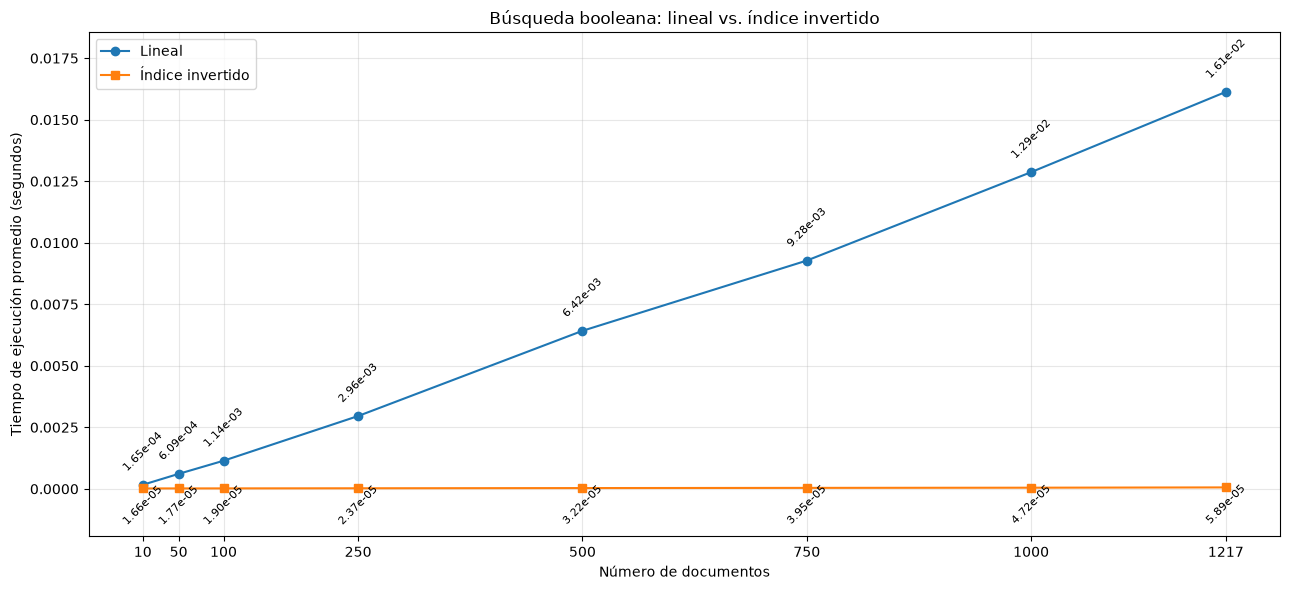

In [25]:
graficar("bool_lineal", "bool_indice", "Búsqueda booleana: lineal vs. índice invertido")

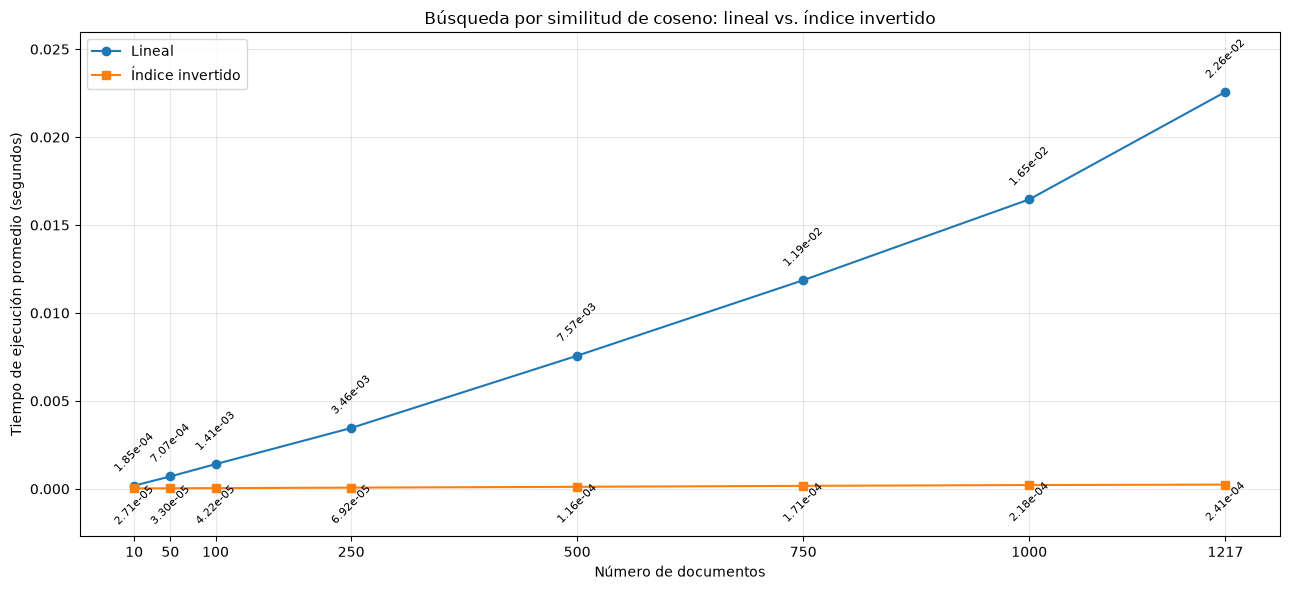

In [26]:
graficar("cos_lineal", "cos_indice", "Búsqueda por similitud de coseno: lineal vs. índice invertido")

## Parte 6: Análisis de Resultados

**1. Complejidad**

| Enfoque | Complejidad |
|---|---|
| Booleana lineal | O(N): revisa el BoW de cada documento una vez |
| Booleana con índice | O(n + m): recorre las dos posting lists una sola vez |
| Coseno lineal | O(total de palabras de la colección): visita los N documentos y recalcula la norma de cada uno recorriendo todo su BoW |
| Coseno con índice | O(P + C log C): P es la suma de los largos de las posting lists de la consulta y C la cantidad de candidatos que se ordenan al final |

Los tiempos son consistentes con esto. Al pasar de 100 a 1000 documentos (10 veces más), la booleana lineal sube de 0.001143 s a 0.012869 s (×11.3) y el coseno lineal de 0.001405 s a 0.016458 s (×11.7), por eso sus curvas son casi rectas. Las versiones con índice también crecen, porque con más documentos las posting lists son más largas, pero mucho menos: la booleana pasa de 0.000019 s a 0.000047 s (×2.5) y el coseno de 0.000042 s a 0.000218 s (×5.2). En colecciones chicas el tiempo del índice casi no cambia porque domina un costo fijo: preprocesar los términos de la consulta.

**2. Punto de quiebre**

Midiendo solo el tiempo de consulta, el índice es más rápido desde el tamaño más chico que probamos (10 documentos) en los dos tipos de búsqueda: 0.000017 s contra 0.000165 s en la booleana (unas 10 veces más rápido) y 0.000027 s contra 0.000185 s en coseno (unas 7 veces). Los dos puntos de quiebre coinciden y están por debajo de 10 documentos. La ventaja crece con N: con 1217 documentos el índice es 274 veces más rápido en la booleana y 94 veces en coseno. En la booleana la diferencia es mayor en parte porque la versión lineal recorre el DataFrame con `iterrows`, que es lento.

**3. Overhead**

Sí. El costo adicional está en construir el índice: leer los BoW desde PostgreSQL, armar las posting lists y calcular el idf y las normas. Con 10 documentos la construcción tarda 0.0108 s, y ese tiempo recién se recupera después de unas 73 consultas booleanas o 69 de coseno (construcción / (t_lineal − t_índice)). Con 1217 documentos se recupera mucho antes: en unas 12 consultas booleanas o 9 de coseno. Además, el índice ocupa memoria extra.

**4. Exactitud**

Sí, son idénticos. En los 8 tamaños las columnas `bool_iguales` y `cos_iguales` salieron `True`: las búsquedas booleanas devuelven el mismo conjunto de documentos y las de coseno el mismo top 5, con una diferencia de 0.0 en los scores. Es lo esperado: las dos versiones aplican la misma fórmula y hacen las mismas sumas en el mismo orden. El índice solo se salta los documentos que no comparten ningún término con la consulta, cuyo coseno sería 0 de todas formas. Podrían aparecer diferencias en dos casos: si las sumas se hicieran en otro orden (redondeo de punto flotante en los últimos decimales), o si un término de la consulta tuviera idf 0, porque la versión con índice incluiría documentos con score 0 que la lineal descarta con `if punto > 0`. En nuestra colección ningún término tiene idf 0.

**5. Limitaciones**

Con 100 veces más documentos (unas 121 700 noticias), el problema es que todo vive en memoria RAM: las posting lists, el idf, las normas, y además los BoW y textos que la clase guarda en `_bows` y `_docs`. Podría no caber en memoria. Además, el índice se reconstruye cada vez que se ejecuta el programa, y la construcción crece con N (de 0.011 s con 10 documentos a 0.19 s con 1217). La alternativa es guardar el índice en disco, por ejemplo en una tabla de PostgreSQL con (término, doc_id, tf), y leer solo las posting lists de los términos de la consulta. Como indica el PPT, en disco conviene que cada posting list esté guardada de forma continua para leerla de una sola vez.